# 10. Model Evaluation

## 1. Introduction

This stage evaluates the final tuned model using an independent
test dataset.

The test set has not been used for:

- Model training
- Hyperparameter tuning
- Model selection
- Threshold optimization

The purpose is to estimate the final model's generalization
performance on unseen transactions.

In [23]:
import json
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
)

from src.config import (
    CLEANED_DATA_PATH,
    TARGET_COLUMN,
    RANDOM_STATE,
    TEST_SIZE,
    TUNED_MODEL_PATH,
    METRICS_DIR,
    THRESHOLD_PATH,
)

from src.evaluate import (
    evaluate_model,
    get_prediction_probabilities,
    calculate_metrics,
    load_threshold,
)

METRICS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

## 2. Recreating the Test Dataset

The same random seed and splitting strategy used during
the previous stages must be applied.

The test dataset contains 20% of the original observations.

Stratification preserves the original target distribution.

In [24]:
df = pd.read_csv(CLEANED_DATA_PATH)

X = df.drop(columns=[TARGET_COLUMN])

y = df[TARGET_COLUMN]

X_development, X_test, y_development, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE
)

X_train, X_validation, y_train, y_validation = train_test_split(
    X_development,
    y_development,
    test_size=0.20,
    stratify=y_development,
    random_state=RANDOM_STATE
)

print("Test Shape:", X_test.shape)

print("\nTest Class Distribution:")

print(y_test.value_counts())

Test Shape: (56962, 30)

Test Class Distribution:
Class
0    56864
1       98
Name: count, dtype: int64


## 3. Loading the Final Model

The tuned model is loaded from the models directory.

The saved artifact contains the complete prediction pipeline.

No preprocessing or sampling is fitted again during
the evaluation stage.

In [25]:
model = joblib.load(
    TUNED_MODEL_PATH
)

threshold = load_threshold(
    THRESHOLD_PATH
)

print("Model loaded successfully.")

print("Selected Threshold:", threshold)

Model loaded successfully.
Selected Threshold: 0.6522238095238094


## 4. Final Test Evaluation

The final model is evaluated using the selected validation
threshold.

The following metrics are reported:

- Accuracy
- Precision
- Recall
- F1-Score
- ROC-AUC
- Average Precision
- MCC
- Balanced Accuracy

Average Precision is especially useful for evaluating
performance under severe class imbalance.


Classification Metrics
----------------------
threshold: 0.6522
accuracy: 0.9995
precision: 0.9080
recall: 0.8061
f1_score: 0.8541
roc_auc: 0.9822
average_precision: 0.8643
mcc: 0.8553
balanced_accuracy: 0.9030

Classification Report
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     56864
       Fraud       0.91      0.81      0.85        98

    accuracy                           1.00     56962
   macro avg       0.95      0.90      0.93     56962
weighted avg       1.00      1.00      1.00     56962



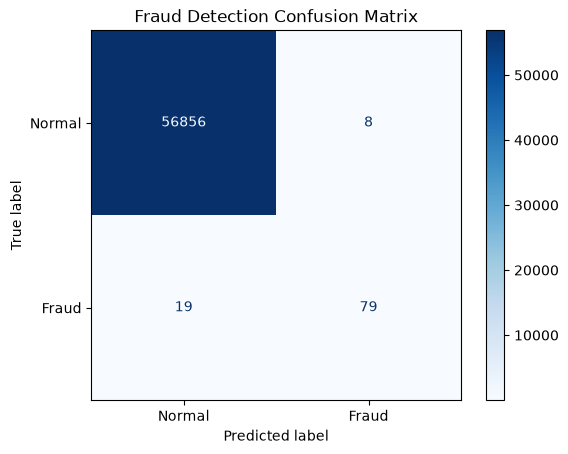

In [26]:
test_metrics = evaluate_model(
    model,
    X_test,
    y_test,
    threshold=threshold
)

## 5. Confusion Matrix Analysis

The confusion matrix contains four outcomes:

- True Negative (TN): Legitimate transaction correctly classified.
- False Positive (FP): Legitimate transaction incorrectly classified as fraud.
- False Negative (FN): Fraudulent transaction incorrectly classified as legitimate.
- True Positive (TP): Fraudulent transaction correctly classified.

False negatives are particularly important because they
represent fraudulent transactions that were not detected.

In [27]:
y_test_prob = get_prediction_probabilities(
    model,
    X_test
)

y_test_pred = (
    y_test_prob >= threshold
).astype(int)

cm = confusion_matrix(
    y_test,
    y_test_pred
)

tn, fp, fn, tp = cm.ravel()

print("True Negatives:", tn)

print("False Positives:", fp)

print("False Negatives:", fn)

print("True Positives:", tp)

print("\nConfusion Matrix:")

print(cm)

True Negatives: 56856
False Positives: 8
False Negatives: 19
True Positives: 79

Confusion Matrix:
[[56856     8]
 [   19    79]]


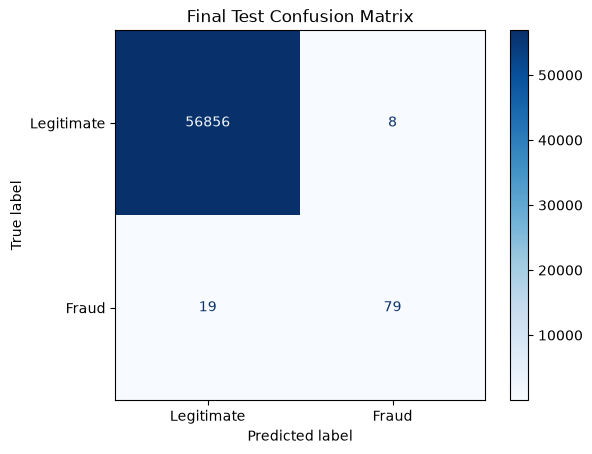

In [28]:
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Legitimate",
        "Fraud"
    ]
)

display.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("Final Test Confusion Matrix")

plt.savefig(
    METRICS_DIR / "final_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 6. Classification Report

The classification report provides Precision, Recall,
and F1-Score for each class.

The fraud class is particularly important because
the project's primary objective is detecting fraudulent
transactions.

In [29]:
print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=[
            "Legitimate",
            "Fraud"
        ],
        zero_division=0
    )
)

              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56864
       Fraud       0.91      0.81      0.85        98

    accuracy                           1.00     56962
   macro avg       0.95      0.90      0.93     56962
weighted avg       1.00      1.00      1.00     56962



## 7. ROC Curve

The ROC curve illustrates the relationship between
the True Positive Rate and the False Positive Rate
across different classification thresholds.

ROC-AUC measures the model's ability to rank positive
observations above negative observations.

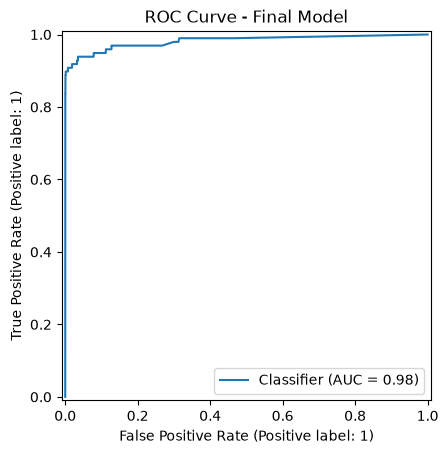

In [30]:
RocCurveDisplay.from_predictions(
    y_test,
    y_test_prob
)

plt.title("ROC Curve - Final Model")

plt.savefig(
    METRICS_DIR / "roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 8. Precision-Recall Curve

The Precision-Recall curve is particularly informative
for imbalanced classification problems.

It illustrates the trade-off between Precision and Recall
at different classification thresholds.

Average Precision summarizes the precision-recall curve
using a weighted average of precision values.

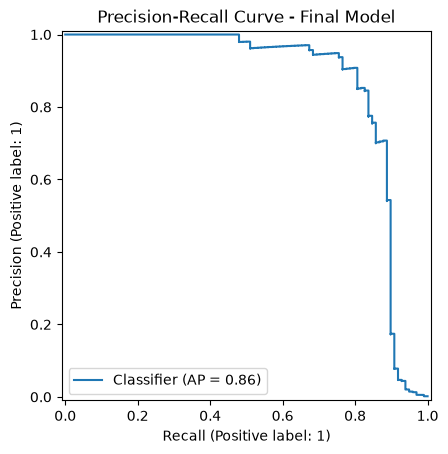

In [31]:
PrecisionRecallDisplay.from_predictions(
    y_test,
    y_test_prob
)

plt.title("Precision-Recall Curve - Final Model")

plt.savefig(
    METRICS_DIR / "precision_recall_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 9. Saving Final Evaluation Results

The final evaluation metrics are saved as a CSV file.

The generated plots are stored in the reports/metrics directory.

These artifacts will be used in the final project report.

In [32]:
from IPython.display import display

metrics_df = pd.DataFrame(
    [test_metrics]
)

metrics_df.to_csv(
    METRICS_DIR / "final_test_metrics.csv",
    index=False
)

print("Final test metrics saved successfully.")

display(metrics_df)

Final test metrics saved successfully.


,threshold,accuracy,precision,recall,f1_score,roc_auc,average_precision,mcc,balanced_accuracy
0,0.652224,0.999526,0.908046,0.806122,0.854054,0.982174,0.864264,0.855336,0.902991


In [33]:
from IPython.display import display

confusion_summary = pd.DataFrame(
    {
        "Actual Class": [
            "Legitimate",
            "Legitimate",
            "Fraud",
            "Fraud"
        ],
        "Predicted Class": [
            "Legitimate",
            "Fraud",
            "Legitimate",
            "Fraud"
        ],
        "Count": [
            tn,
            fp,
            fn,
            tp
        ]
    }
)

confusion_summary.to_csv(
    METRICS_DIR / "confusion_matrix_values.csv",
    index=False
)

display(confusion_summary)

,Actual Class,Predicted Class,Count
0,Legitimate,Legitimate,56856
1,Legitimate,Fraud,8
2,Fraud,Legitimate,19
3,Fraud,Fraud,79


## 10. Final Evaluation Conclusion

The final model is evaluated using an independent test set.

The final report should discuss:

1. Overall predictive performance.
2. Fraud detection Recall.
3. Fraud detection Precision.
4. False Positive count.
5. False Negative count.
6. ROC-AUC.
7. Average Precision.
8. Whether the selected threshold is appropriate.

The results must be interpreted in the context of the
dataset and the business cost of different classification errors.

No performance value should be reported without being
generated from the actual experiment.